<a href="https://colab.research.google.com/github/mihaipopa15/unit-testing-junit/blob/main/lab4ex3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import numpy as np

np.random.seed(42)
X = np.random.rand(160,1) - 1
y = 2 * (X[:, 0])**2 + 0.2 * np.random.randn(160)

In [5]:
from sklearn.tree import DecisionTreeRegressor

tree_reg1 = DecisionTreeRegressor(max_depth=2, random_state=42)
tree_reg1.fit(X, y)

DecisionTreeRegressor(max_depth=2, random_state=42)

In [6]:
y2 = y - tree_reg1.predict(X)
tree_reg2 = DecisionTreeRegressor(max_depth=2, random_state=42)
tree_reg2.fit(X, y2)

DecisionTreeRegressor(max_depth=2, random_state=42)

In [7]:
y3 = y2 - tree_reg2.predict(X)
tree_reg3 = DecisionTreeRegressor(max_depth=2, random_state=42)
tree_reg3.fit(X, y3)

DecisionTreeRegressor(max_depth=2, random_state=42)

In [8]:
X_new = np.array([[0.8]])

In [9]:
y_pred = sum(tree.predict(X_new) for tree in (tree_reg1, tree_reg2, tree_reg3))
y_pred

array([0.11000187])

In [10]:
def plot_predictions(regressors, X, y, axes, label=None, style="r-", data_style="b.", data_label=None):
    x1 = np.linspace(axes[0], axes[1], 500)
    y_pred = sum(regressor.predict(x1.reshape(-1, 1)) for regressor in regressors)
    plt.plot(X[:, 0], y, data_style, label=data_label)
    plt.plot(x1, y_pred, style, linewidth=2, label=label)
    if label or data_label:
        plt.legend(loc="upper center", fontsize=16)
    plt.axis(axes)

In [14]:
from sklearn.ensemble import GradientBoostingRegressor

gbrt = GradientBoostingRegressor(max_depth=2, n_estimators=100, learning_rate=1.0, random_state=42)
gbrt.fit(X, y)

GradientBoostingRegressor(learning_rate=1.0, max_depth=2, random_state=42)

In [13]:
gbrt_slow = GradientBoostingRegressor(max_depth=2, n_estimators=200, learning_rate=0.1, random_state=42)
gbrt_slow.fit(X, y)

GradientBoostingRegressor(max_depth=2, n_estimators=200, random_state=42)

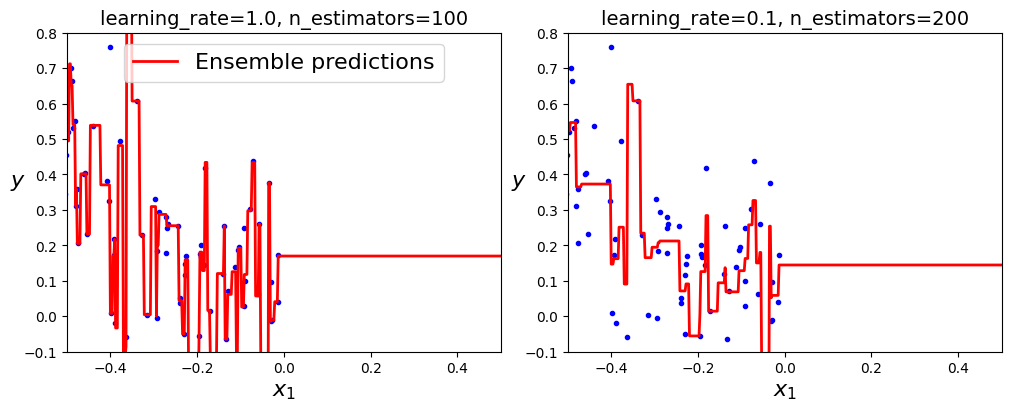

In [16]:
import matplotlib.pyplot as plt

fix, axes = plt.subplots(ncols=2, figsize=(10,4), constrained_layout=True)

plt.sca(axes[0])
plot_predictions([gbrt], X, y, axes=[-0.5, 0.5, -0.1, 0.8], label="Ensemble predictions")
plt.title("learning_rate={}, n_estimators={}".format(gbrt.learning_rate, gbrt.n_estimators), fontsize=14)
plt.xlabel("$x_1$", fontsize=16)
plt.ylabel("$y$", fontsize=16, rotation=0)

plt.sca(axes[1])
plot_predictions([gbrt_slow], X, y, axes=[-0.5, 0.5, -0.1, 0.8])
plt.title("learning_rate={}, n_estimators={}".format(gbrt_slow.learning_rate, gbrt_slow.n_estimators), fontsize=14)
plt.xlabel("$x_1$", fontsize=16)
plt.ylabel("$y$", fontsize=16, rotation=0)

plt.show()

Optimal number of trees: 39 (Validation MSE: 0.0429)


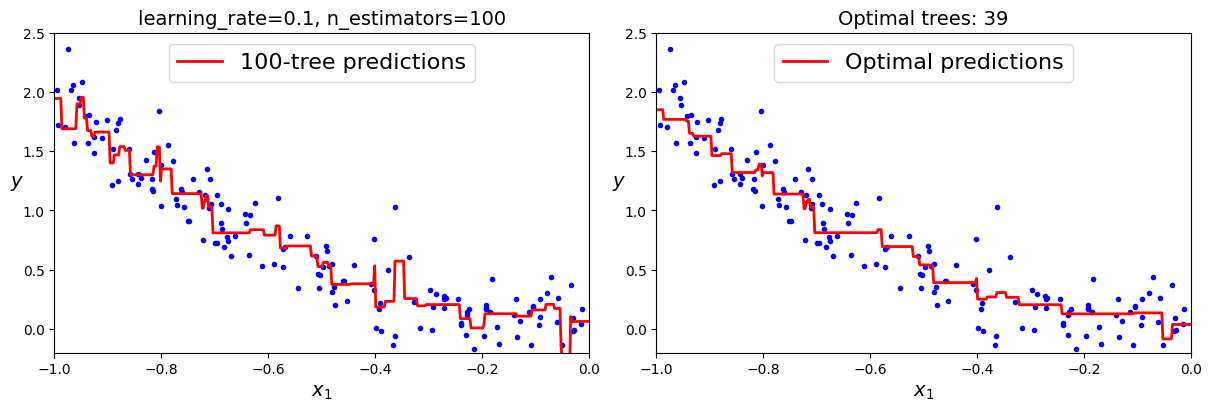

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# Split the dataset: 75% train, 25% validation
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.25, random_state=42)

# Train 100-tree model
gbrt_100 = GradientBoostingRegressor(max_depth=2, n_estimators=100, learning_rate=0.1, random_state=42)
gbrt_100.fit(X_train, y_train)

# Find the optimal number of trees using staged_predict validation errors
errors = [mean_squared_error(y_val, y_pred) for y_pred in gbrt_100.staged_predict(X_val)]
best_n_estimators = np.argmin(errors) + 1
min_error = errors[best_n_estimators - 1]
print(f"Optimal number of trees: {best_n_estimators} (Validation MSE: {min_error:.4f})")

# Train the optimized model with the best number of trees
gbrt_best = GradientBoostingRegressor(max_depth=2, n_estimators=best_n_estimators, learning_rate=0.1, random_state=42)
gbrt_best.fit(X_train, y_train)

# Plot both model predictions
fig, axes = plt.subplots(ncols=2, figsize=(12, 4), constrained_layout=True)

# Plot 1) 100-tree predictions
plt.sca(axes[0])
plot_predictions([gbrt_100], X, y, axes=[-1, 0, -0.2, 2.5], label="100-tree predictions")
plt.title(f"learning_rate=0.1, n_estimators=100", fontsize=14)
plt.xlabel("$x_1$", fontsize=14)
plt.ylabel("$y$", fontsize=14, rotation=0)

# Plot 2) Optimal predictions
plt.sca(axes[1])
plot_predictions([gbrt_best], X, y, axes=[-1, 0, -0.2, 2.5], label="Optimal predictions")
plt.title(f"Optimal trees: {best_n_estimators}", fontsize=14)
plt.xlabel("$x_1$", fontsize=14)
plt.ylabel("$y$", fontsize=14, rotation=0)

plt.show()